# Proyecto integrador: ¿qué se asocia con la calidad del sueño?

En este proyecto aplicamos, sobre un único conjunto de datos, las herramientas de los seis módulos del curso: describir una variable, estimar con incertidumbre, comparar grupos, estudiar relaciones y planificar un estudio. La pregunta guía es:

> ¿Qué características de las personas se asocian con su **calidad del sueño** (`SQ`, escala de 1 a 10)?

Usamos los datos de salud del sueño preparados en la práctica de preprocesamiento del Módulo 1. Recuerda que son **sintéticos**, creados con fines ilustrativos, y que el estudio es **observacional**: podremos describir asociaciones, pero no demostrar causas.

Cada apartado plantea una tarea. Intenta resolverla antes de desplegar la solución.

::: {.callout-note appearance="simple"}
## Ejecutar este cuaderno

- [Abrir en Google Colab](https://colab.research.google.com/github/JulioUQ/Curso-de-Estadistica-Basica/blob/main/notebooks/07_proyecto_integrador/practica.ipynb)
- [Ver o descargar el cuaderno en GitHub](https://github.com/JulioUQ/Curso-de-Estadistica-Basica/blob/main/notebooks/07_proyecto_integrador/practica.ipynb) (botón *Download raw file*)
- Para trabajar en tu ordenador, descarga el [repositorio completo](https://github.com/JulioUQ/Curso-de-Estadistica-Basica/archive/refs/heads/main.zip): el cuaderno necesita la librería `src/stats_toolkit` y los datos del curso. Las instrucciones de instalación están en el archivo `README.md`.

La celda siguiente solo actúa en Google Colab: descarga el repositorio del curso, instala las bibliotecas que falten y se sitúa en la carpeta de este cuaderno. Si instala o actualiza alguna, te pedirá que reinicies la sesión y vuelvas a ejecutar el cuaderno. En tu ordenador no hace nada.
:::

In [1]:
# Solo en Google Colab: descarga el repositorio del curso (stats_toolkit y datos),
# instala las bibliotecas que falten y se sitúa en la carpeta de este cuaderno.
# En otro entorno (tu ordenador, la web del curso) no hace nada.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    from importlib.metadata import PackageNotFoundError, version

    repo = "/content/Curso-de-Estadistica-Basica"
    if not os.path.isdir(repo):
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/JulioUQ/Curso-de-Estadistica-Basica.git", repo], check=True)

    # Bibliotecas de cálculo de requirements.txt (Jupyter ya viene con Colab).
    with open(f"{repo}/requirements.txt", encoding="utf-8") as f:
        requisitos = [linea.split("#")[0].strip() for linea in f]
    requisitos = [r for r in requisitos if r and r not in ("jupyter", "ipykernel", "nbclient", "nbformat")]
    nombres = [r.split(">=")[0] for r in requisitos]

    def versiones():
        res = {}
        for n in nombres:
            try:
                res[n] = version(n)
            except PackageNotFoundError:
                res[n] = None
        return res

    antes = versiones()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requisitos], check=True)
    cambiadas = [n for n, v in versiones().items() if v != antes[n]]
    if cambiadas:
        print("Se han instalado o actualizado:", ", ".join(cambiadas))
        print("Reinicia la sesión (menú «Entorno de ejecución») y vuelve a ejecutar el cuaderno.")
    os.chdir(f"{repo}/notebooks/07_proyecto_integrador")

## Preparación

In [2]:
import sys
sys.path.append("../../src")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from stats_toolkit import descriptive as desc
from stats_toolkit import group_comparisons as gc
from stats_toolkit import inference as inf
from stats_toolkit import regression as reg

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)  # tamaño común de las figuras de una sola gráfica
ALPHA = 0.05
SEED = 42

DATA_PATH = Path("../01_estadistica_descriptiva/data/sleephealth_processed.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró {DATA_PATH}. Ejecuta antes la práctica "
        "'practica_preprocesamiento.ipynb' del Módulo 1, que genera este archivo."
    )
# keep_default_na=False: en SD, "None" es una categoría (sin trastorno), no un valor ausente.
sueno = pd.read_csv(DATA_PATH, keep_default_na=False, na_values=[""])
print(f"{sueno.shape[0]} personas y {sueno.shape[1]} variables")
sueno[["Gender", "Age", "SH", "SQ", "PHY", "Stress", "SD"]].head()

373 personas y 15 variables


,Gender,Age,SH,SQ,PHY,Stress,SD
0,Male,27.0,6.1,6,42,6,None
1,Male,28.0,6.2,6,60,8,None
2,Male,28.0,6.2,6,60,8,None
3,Male,28.0,5.9,4,30,8,Sleep Apnea
4,Male,28.0,5.9,4,30,8,Sleep Apnea


## Describir la variable respuesta (Módulo 1)

**Tarea.** Resume la calidad del sueño (`SQ`): tendencia central, dispersión, forma y frecuencia de cada valor. ¿Qué tipo de variable es y qué gráfico es adecuado?

::: {.callout-tip collapse="true"}
## Solución

`SQ` toma pocos valores enteros, así que la representamos con un diagrama de barras de frecuencias en lugar de un histograma.

n                 373.000
media               7.316
mediana             7.000
desv. típica        1.197
Q1                  6.000
Q3                  8.000
asimetría (G1)     -0.213
curtosis (G2)      -0.741


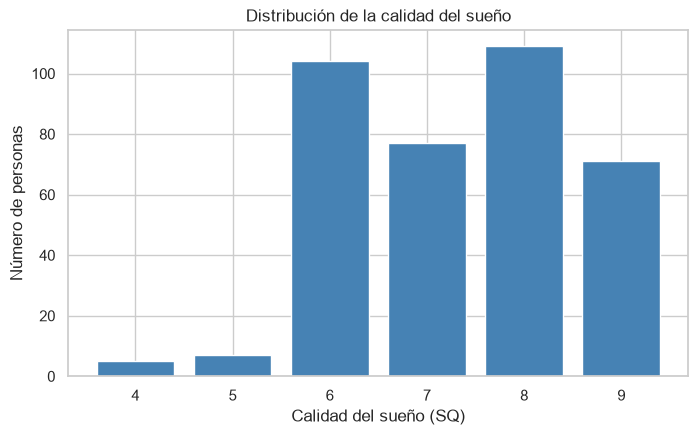

In [3]:
#| fig-alt: "Diagrama de barras con el número de personas para cada valor de la calidad del sueño, de 4 a 9. Los valores 4 y 5 son poco frecuentes y la mayoría de las personas puntúan entre 6 y 9."
sq = sueno["SQ"].to_numpy(float)
res = desc.summary_statistics(sq)
tabla = pd.Series({
    "n": res["n"],
    "media": res["central_tendency"]["mean"],
    "mediana": res["central_tendency"]["median"],
    "desv. típica": res["dispersion"]["std"],
    "Q1": res["five_number_summary"]["q1"],
    "Q3": res["five_number_summary"]["q3"],
    "asimetría (G1)": res["shape"]["skewness"],
    "curtosis (G2)": res["shape"]["kurtosis_excess"],
}).round(3)
print(tabla.to_string())

frecuencias = sueno["SQ"].value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(frecuencias.index, frecuencias.values, color="steelblue")
ax.set_title("Distribución de la calidad del sueño")
ax.set_xlabel("Calidad del sueño (SQ)")
ax.set_ylabel("Número de personas")
plt.show()

La calidad media es 7,32 y la mediana 7, con una desviación típica de 1,2 puntos. La asimetría es ligeramente negativa ($G_1 \approx -0{,}21$) y el exceso de curtosis es negativo ($G_2 \approx -0{,}74$), propio de una variable con pocos valores posibles y sin colas largas. `SQ` es una puntuación entera (cuantitativa discreta, o una escala ordinal si dudamos de que las distancias entre puntuaciones sean iguales): en estos datos solo toma valores entre 4 y 9, y los valores 4 y 5 son poco frecuentes.
:::

## Estimar con incertidumbre (Módulos 3 y 4)

**Tarea.** Construye un intervalo de confianza del 95 % para la media de `SQ` con la t de Student y compáralo con un intervalo bootstrap. ¿Por qué es razonable usar la t aunque `SQ` no sea Normal?

::: {.callout-tip collapse="true"}
## Solución

Con $n = 373$ observaciones independientes, el Teorema Central del Límite hace que la media muestral sea aproximadamente Normal aunque `SQ` sea discreta y no simétrica.

In [4]:
low_t, up_t = inf.confidence_interval_mean_t(sq.mean(), sq.std(ddof=1), sq.size)
low_b, up_b = inf.bootstrap_ci(sq, np.mean, n_resamples=10_000, seed=SEED)
print(f"Media de SQ: {sq.mean():.3f}")
print(f"IC t del 95 %:         ({low_t:.3f}, {up_t:.3f})")
print(f"IC bootstrap del 95 %: ({low_b:.3f}, {up_b:.3f})")

Media de SQ: 7.316
IC t del 95 %:         (7.195, 7.438)
IC bootstrap del 95 %: (7.198, 7.440)


Los dos intervalos son prácticamente iguales, alrededor de (7,20; 7,44): el método t, justificado por el TCL, y el bootstrap, que no usa ninguna fórmula para el error estándar, dan la misma respuesta. Como en todo intervalo de confianza, el 95 % se refiere al procedimiento: acierta en el 95 % de las muestras posibles.
:::

## Comparar dos grupos (Módulo 4)

**Tarea.** Divide a las personas según su nivel de actividad física (`PHY`), por encima o no de la mediana. ¿Difiere la calidad del sueño entre los dos grupos? Usa la t de Welch y, como comprobación, la prueba de Mann-Whitney.

::: {.callout-tip collapse="true"}
## Solución

Usamos Welch porque no exige varianzas iguales. Contraste bilateral: $H_0: \mu_{\text{alta}} = \mu_{\text{baja}}$ frente a $H_1: \mu_{\text{alta}} \neq \mu_{\text{baja}}$.

In [5]:
mediana_phy = sueno["PHY"].median()
alta = sueno.loc[sueno["PHY"] > mediana_phy, "SQ"].to_numpy(float)
baja = sueno.loc[sueno["PHY"] <= mediana_phy, "SQ"].to_numpy(float)
t_w, p_w, gl_w = inf.welch_t_test(alta, baja)
u, p_u = gc.mann_whitney_u(alta, baja)
print(f"Mediana de PHY: {mediana_phy}")
print(f"Actividad alta: n = {alta.size}, media SQ = {alta.mean():.2f}")
print(f"Actividad baja: n = {baja.size}, media SQ = {baja.mean():.2f}")
print(f"Diferencia de medias: {alta.mean() - baja.mean():.2f}")
print(f"Welch: t = {t_w:.2f}, gl = {gl_w:.1f}, p-valor = {p_w:.3g}")
print(f"Mann-Whitney: U = {u:.0f}, p-valor = {p_u:.3g}")

Mediana de PHY: 60.0
Actividad alta: n = 143, media SQ = 7.59
Actividad baja: n = 230, media SQ = 7.15
Diferencia de medias: 0.44
Welch: t = 3.57, gl = 320.9, p-valor = 0.000407
Mann-Whitney: U = 19644, p-valor = 0.0011


Las personas con actividad física por encima de la mediana tienen una calidad media 0,44 puntos mayor (7,59 frente a 7,15). Los grupos no tienen el mismo tamaño porque 70 personas tienen exactamente el valor mediano (60), que hemos asignado al grupo de actividad baja. Welch rechaza la igualdad de medias ($p \approx 0{,}0004$) y Mann-Whitney apunta en la misma dirección ($p \approx 0{,}001$). Es una asociación: las personas más activas pueden diferir también en estrés, edad u ocupación.
:::

## Comparar varios grupos (Módulo 6)

**Tarea.** ¿Difiere la calidad del sueño según el trastorno del sueño (`SD`: sin trastorno, insomnio o apnea)? Aplica un ANOVA de un factor, mide el tamaño del efecto con $\eta^2$, identifica qué parejas difieren con Tukey y contrasta el resultado con Kruskal-Wallis.

::: {.callout-tip collapse="true"}
## Solución

Sin trastorno: n = 218, media SQ = 7.63
Insomnio: n = 77, media SQ = 6.53
Apnea del sueño: n = 78, media SQ = 7.21
ANOVA: F = 28.05, p-valor = 4.53e-12; eta² = 0.132
Kruskal-Wallis: H = 49.90, p-valor = 1.46e-11


,grupo_1,grupo_2,diferencia,p_valor,ic_inferior,ic_superior
0,Sin trastorno,Insomnio,1.101,2.27e-12,0.752,1.449
1,Sin trastorno,Apnea del sueño,0.428,0.011,0.081,0.775
2,Insomnio,Apnea del sueño,-0.673,0.000611,-1.095,-0.250


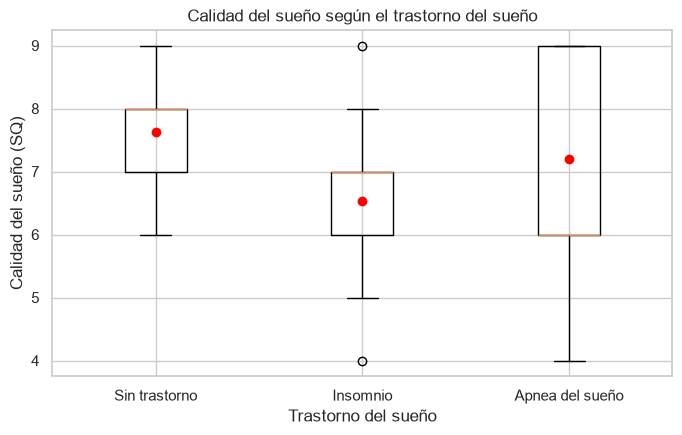

In [6]:
#| fig-alt: "Diagramas de caja de la calidad del sueño por trastorno, con la media como un punto rojo. Sin trastorno: caja de 7 a 8, mediana 8 y media de unos 7,6. Insomnio: caja de 6 a 7, mediana 7 y media de unos 6,5. Apnea del sueño: caja muy amplia, de 6 a 9, con mediana 6 y media de unos 7,2."
niveles = ["None", "Insomnia", "Sleep Apnea"]
etiquetas = ["Sin trastorno", "Insomnio", "Apnea del sueño"]
grupos_sd = [sueno.loc[sueno["SD"] == g, "SQ"].to_numpy(float) for g in niveles]

f_sd, p_sd = gc.anova_one_way(*grupos_sd)
eta2_sd = gc.eta_squared(*grupos_sd)
h_sd, p_kw = gc.kruskal_wallis(*grupos_sd)
for e, g in zip(etiquetas, grupos_sd):
    print(f"{e}: n = {g.size}, media SQ = {g.mean():.2f}")
print(f"ANOVA: F = {f_sd:.2f}, p-valor = {p_sd:.3g}; eta² = {eta2_sd:.3f}")
print(f"Kruskal-Wallis: H = {h_sd:.2f}, p-valor = {p_kw:.3g}")
tukey = gc.tukey_hsd(*grupos_sd, labels=etiquetas)
tukey["p_valor"] = tukey["p_valor"].map(lambda p: f"{p:.3g}")  # sin redondear a 0
display(tukey.round(3))

fig, ax = plt.subplots()
ax.boxplot(grupos_sd, tick_labels=etiquetas, showmeans=True,
           meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red"})
ax.set_title("Calidad del sueño según el trastorno del sueño")
ax.set_xlabel("Trastorno del sueño")
ax.set_ylabel("Calidad del sueño (SQ)")
plt.show()

Las medias son 7,63 sin trastorno, 7,21 con apnea y 6,53 con insomnio. El ANOVA es claramente significativo y $\eta^2 = 0{,}13$: el trastorno se asocia con alrededor del 13 % de la variabilidad de la calidad del sueño. Tukey indica que las tres parejas difieren (todos los p-valores ajustados son menores que 0,05); la mayor diferencia es la de sin trastorno frente a insomnio, de 1,1 puntos.

El gráfico obliga a matizar. El grupo con apnea es mucho más disperso que los otros dos (su caja va de 6 a 9) y su mediana, 6, está por debajo de su media: el supuesto de varianzas iguales del ANOVA es dudoso y la media no resume bien a ese grupo. Kruskal-Wallis, que no supone normalidad, también rechaza la igualdad, lo que refuerza la conclusión general, pero conviene describir cada grupo con algo más que su media.
:::

## Relación con una variable numérica (Módulo 5)

**Tarea.** Estudia la relación entre las horas de sueño (`SH`) y su calidad (`SQ`): calcula las correlaciones de Pearson y Spearman, ajusta una regresión lineal simple de `SQ` sobre `SH` con el intervalo de confianza de la pendiente y revisa los residuos.

::: {.callout-tip collapse="true"}
## Solución

Pearson r = 0.882; Spearman rho = 0.887 (p-valor = 2.29e-126)
SQ estimada = -2.16 + 1.33 × SH;  R² = 0.779
IC 95 % para la pendiente: (1.256, 1.400)


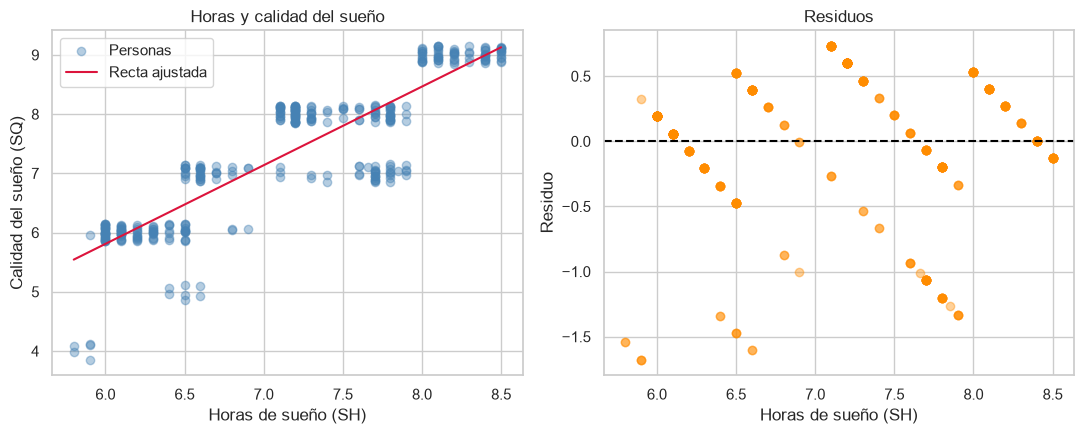

In [7]:
#| fig-alt: "Dos gráficos. A la izquierda, diagrama de dispersión de la calidad del sueño frente a las horas de sueño, con los puntos desplazados ligeramente en vertical para que no se solapen y la recta de regresión creciente en rojo: la calidad sube por escalones al aumentar las horas. A la derecha, los residuos frente a las horas de sueño forman franjas diagonales alrededor de la línea discontinua en cero."
sh = sueno["SH"].to_numpy(float)
r_sh = reg.correlation(sh, sq)
rho_sh, p_rho = reg.spearman_test(sh, sq)
b0, b1 = reg.simple_linear_regression(sh, sq)
r2 = reg.r_squared(sh, sq, b0, b1)
low_b1, up_b1 = reg.confidence_interval_slope(sh, sq, b0, b1)
print(f"Pearson r = {r_sh:.3f}; Spearman rho = {rho_sh:.3f} (p-valor = {p_rho:.3g})")
print(f"SQ estimada = {b0:.2f} + {b1:.2f} × SH;  R² = {r2:.3f}")
print(f"IC 95 % para la pendiente: ({low_b1:.3f}, {up_b1:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
jit = np.random.default_rng(0).uniform(-0.15, 0.15, sq.size)
axes[0].scatter(sh, sq + jit, alpha=0.4, color="steelblue", label="Personas")
xs = np.linspace(sh.min(), sh.max(), 50)
axes[0].plot(xs, reg.predict(xs, b0, b1), color="crimson", label="Recta ajustada")
axes[0].set_title("Horas y calidad del sueño")
axes[0].set_xlabel("Horas de sueño (SH)")
axes[0].set_ylabel("Calidad del sueño (SQ)")
axes[0].legend()
axes[1].scatter(sh, reg.residuals(sh, sq, b0, b1), alpha=0.4, color="darkorange")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuos")
axes[1].set_xlabel("Horas de sueño (SH)")
axes[1].set_ylabel("Residuo")
plt.tight_layout()
plt.show()

La relación es fuerte y creciente: $r = 0{,}88$ y $\rho_s = 0{,}89$. Cada hora adicional de sueño se asocia con una calidad 1,33 puntos mayor en promedio (IC 95 %: 1,26 a 1,40), y `SH` explica el 78 % de la variabilidad de `SQ`. El intercepto negativo (−2,16) no tiene interpretación: corresponde a 0 horas de sueño, muy lejos del rango observado (5,8 a 8,5 horas).

Los residuos forman franjas diagonales porque `SQ` solo toma valores enteros, y no se reparten igual a lo largo de `SH`. La recta resume bien la tendencia, pero los supuestos del modelo (errores normales con varianza constante) solo se cumplen de forma aproximada, así que el intervalo de la pendiente debe tomarse como orientativo.
:::

## Planificar un nuevo estudio (Módulo 4)

**Tarea.** Un nuevo estudio quiere estimar la calidad media del sueño con un margen de error de ±0,1 puntos (confianza del 95 %). Usando la desviación típica observada como valor de $\sigma$, ¿cuántas personas necesita? ¿Y con un margen de ±0,2?

::: {.callout-tip collapse="true"}
## Solución

In [8]:
s_sq = sq.std(ddof=1)
for margen in (0.1, 0.2):
    print(f"Margen ±{margen}: n = {inf.sample_size_mean_ci(margin=margen, sigma=s_sq)}")

Margen ±0.1: n = 551
Margen ±0.2: n = 138


Con $\sigma \approx 1{,}2$ harían falta 551 personas para un margen de ±0,1 puntos y 138 para ±0,2. Reducir el margen a la mitad multiplica el tamaño muestral por 4 (salvo el redondeo), porque el margen es proporcional a $1/\sqrt{n}$.
:::

## Síntesis y límites

**Tarea.** Resume los resultados en una tabla y redacta las conclusiones teniendo en cuenta el tamaño de los efectos, el número de contrastes realizados y el tipo de estudio.

::: {.callout-tip collapse="true"}
## Solución

In [9]:
sintesis = pd.DataFrame([
    {"Análisis": "Actividad física alta vs. baja (Welch)", "Efecto": f"diferencia = {alta.mean() - baja.mean():.2f}", "p-valor": p_w},
    {"Análisis": "Trastorno del sueño (ANOVA)", "Efecto": f"η² = {eta2_sd:.3f}", "p-valor": p_sd},
    {"Análisis": "Horas de sueño (pendiente)", "Efecto": f"β₁ = {b1:.2f} (R² = {r2:.3f})", "p-valor": reg.t_test_slope(sh, sq, b0, b1)[1]},
])
sintesis["p-valor"] = sintesis["p-valor"].map(lambda p: f"{p:.3g}")
sintesis

,Análisis,Efecto,p-valor
0,Actividad física alta vs. baja (Welch),diferencia = 0.44,0.000407
1,Trastorno del sueño (ANOVA),η² = 0.132,4.53e-12
2,Horas de sueño (pendiente),β₁ = 1.33 (R² = 0.779),1.39e-123


Conclusiones:

- Las tres características se asocian con la calidad del sueño, con efectos de distinta magnitud: las horas de sueño muestran la asociación más fuerte ($R^2 \approx 0{,}78$), el trastorno del sueño una moderada ($\eta^2 \approx 0{,}13$) y la actividad física una diferencia de unos 0,4 puntos en una escala de 1 a 10.
- Hemos hecho varios contrastes sobre los mismos datos. Con p-valores tan pequeños las conclusiones no cambian, pero en general hay que tener en cuenta el número de comparaciones (Módulo 6).
- Los p-valores tan pequeños reflejan sobre todo una muestra grande: lo que informa de la importancia práctica es el tamaño de cada efecto.
- Son datos observacionales y sintéticos: describen asociaciones en este conjunto de datos, no efectos causales ni hallazgos sobre la salud real. Una variable como el estrés puede estar relacionada a la vez con varias de ellas (variables de confusión, Módulo 5).
- Para estudiar varias variables a la vez haría falta un modelo de regresión múltiple, que queda fuera de este curso.
:::